# Chapter 3, part 1: S&P 500 and Nasdaq-100 from Yahoo Finance

**Runtime → Run all.** The notebook fetches daily data, tidies it, and redraws the six data figures of the lecture:

| Figure | Content |
|---|---|
| `sp500_price.pdf` | S&P 500 daily closing prices |
| `sp500_returns.pdf` | S&P 500 daily returns (%) |
| `sp500_hist.pdf` | Frequency of S&P 500 returns (blue) and normal with same mean and variance (red) |
| `ndx_price.pdf`, `ndx_returns.pdf`, `ndx_hist.pdf` | Same for the Nasdaq-100 |

It also writes `marketdata_info.tex` with the dates and number of trading days, so the slide captions update themselves.
At the end, a zip with everything is downloaded. Upload its contents to the `graphics/` folder in Overleaf.

In class: change the settings below (period, tickers) and re-run to explore live.

In [ ]:
# --- Settings: edit these during the lecture --------------------------------
YEARS = 1                     # length of the window, ending at the latest trading day
END = None                    # None = today, or e.g. "2025-12-31"

# Yahoo index tickers are price indices (no dividends). For dividend-adjusted
# series, use the ETFs instead: "SPY" (S&P 500) and "QQQ" (Nasdaq-100).
SERIES = {
    "sp500": ("^GSPC", "S&P 500"),
    "ndx":   ("^NDX",  "Nasdaq-100"),
}
OUT = "graphics"              # same name as \\graphicspath in the .tex file

In [ ]:
# --- Packages ----------------------------------------------------------------
!pip -q install yfinance
import os, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats

plt.rcParams.update({"figure.figsize": (6, 4), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.3})
os.makedirs(OUT, exist_ok=True)

In [ ]:
# --- 1. Fetch -----------------------------------------------------------------
end = pd.Timestamp(END) if END else pd.Timestamp.today().normalize() + pd.Timedelta(days=1)
start = end - pd.DateOffset(years=YEARS) - pd.Timedelta(days=7)   # small buffer for the first return
tickers = [t for t, _ in SERIES.values()]
raw = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)
raw["Close"].tail()

Ticker,^GSPC,^NDX
Date,,
2026-10-05,7773.950195,31076.439453
2026-10-06,7818.930176,31224.470703
2026-10-07,7801.770020,31160.080078
2026-10-08,7765.359863,30725.810547
2026-10-09,7811.540039,30883.150391


In [ ]:
# --- 2. Tidy: prices and daily returns in % ------------------------------------
# r_t = (P_t - P_{t-1}) / P_{t-1}, as on the slide (dividends included only if adjusted series are used)
prices = raw["Close"][tickers].dropna()
last = prices.index[-1]
prices = prices[prices.index > last - pd.DateOffset(years=YEARS)]
returns = 100 * prices.pct_change().dropna()

fmt = lambda d: f"{d.day} {d.strftime('%B %Y')}"
info = {
    "start": fmt(prices.index[0]), "end": fmt(prices.index[-1]),
    "retstart": fmt(returns.index[0]),
    "nprice": len(prices), "nret": len(returns),
}
print(info)

summary = pd.DataFrame({
    "Mean daily (%)": returns.mean(), "Std. dev. daily (%)": returns.std(),
    "Annualised mean (%)": returns.mean() * 252, "Annualised vol. (%)": returns.std() * np.sqrt(252),
    "Skewness": returns.skew(), "Excess kurtosis": returns.kurt(),
    "Min (%)": returns.min(), "Max (%)": returns.max(),
}).T
summary.columns = [n for _, n in SERIES.values()]
print("Correlation of daily returns:", round(returns.corr().iloc[0, 1], 3))
summary.round(3)

{'start': '10 October 2025', 'end': '9 October 2026', 'retstart': '13 October 2025', 'nprice': 251, 'nret': 250}
Correlation of daily returns: 0.925


,S&P 500,Nasdaq-100
Mean daily (%),0.074,0.105
Std. dev. daily (%),0.804,1.239
Annualised mean (%),18.533,26.427
Annualised vol. (%),12.762,19.664
Skewness,-0.044,-0.069
Excess kurtosis,0.801,0.760
Min (%),-2.645,-4.769
Max (%),2.913,3.428


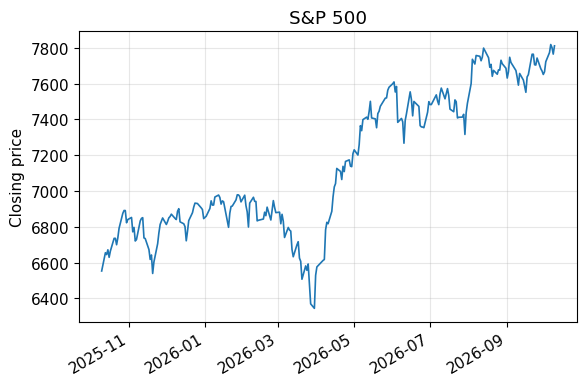

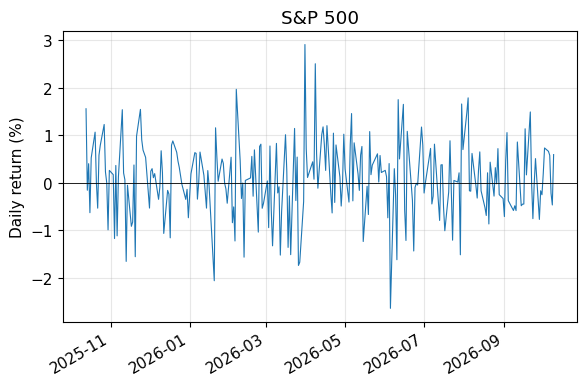

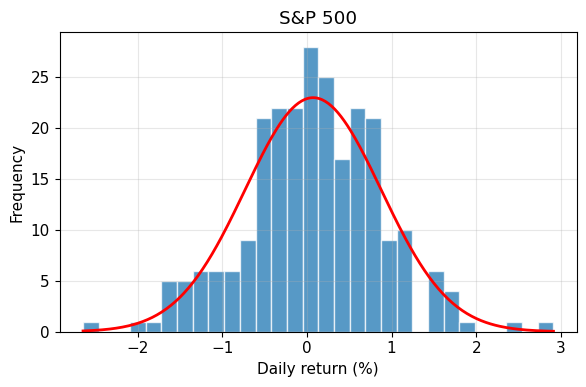

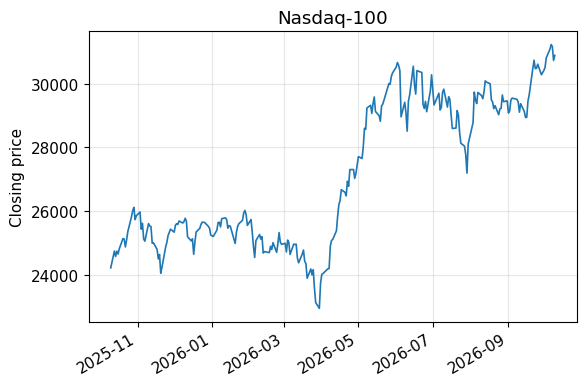

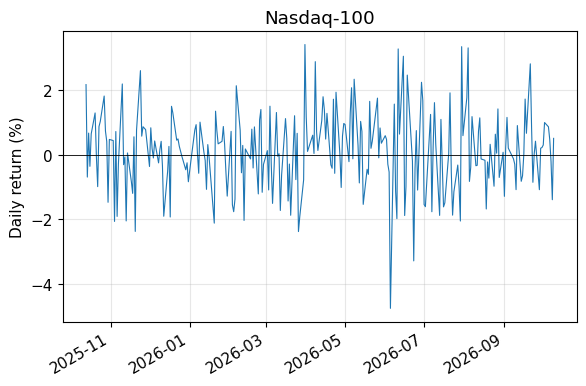

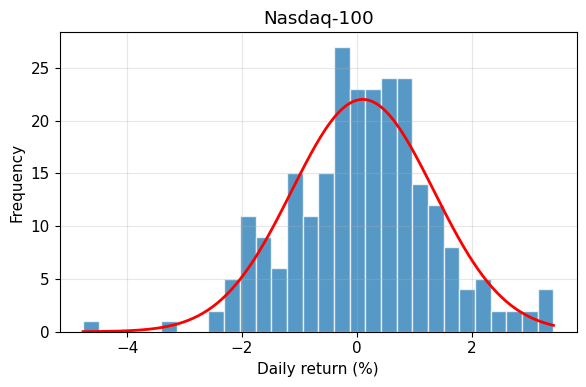

In [ ]:
# --- 3. Figures: price, returns, histogram vs. normal --------------------------
def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{OUT}/{name}.pdf")
    plt.show()

for key, (tic, name) in SERIES.items():
    p, r = prices[tic], returns[tic]

    # Development
    fig, ax = plt.subplots()
    ax.plot(p.index, p, color="tab:blue", lw=1.2)
    ax.set_ylabel("Closing price"); ax.set_title(name)
    fig.autofmt_xdate(); save(fig, f"{key}_price")

    # Daily returns (the 'difference' plot)
    fig, ax = plt.subplots()
    ax.plot(r.index, r, color="tab:blue", lw=0.8)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_ylabel("Daily return (%)"); ax.set_title(name)
    fig.autofmt_xdate(); save(fig, f"{key}_returns")

    # Frequency distribution vs. normal with same mean and variance
    fig, ax = plt.subplots()
    counts, edges, _ = ax.hist(r, bins=30, color="tab:blue", alpha=0.75, edgecolor="white")
    grid = np.linspace(edges[0], edges[-1], 300)
    width = edges[1] - edges[0]
    ax.plot(grid, stats.norm.pdf(grid, r.mean(), r.std()) * len(r) * width, color="red", lw=2)
    ax.set_xlabel("Daily return (%)"); ax.set_ylabel("Frequency"); ax.set_title(name)
    save(fig, f"{key}_hist")

## 5. Efficient frontier and Capital Market Line (block 3)

Pick a handful of stocks, set the risk-free rate, and run. The cell computes annualised expected returns and the covariance matrix from historical daily returns, then draws
* 5 000 random long-only portfolios (the *Markowitz bullet*),
* the efficient frontier, the minimum-variance portfolio and the tangency portfolio M,
* the Capital Market Line from $r_f$ through M.

Historical means are noisy estimates of expected returns, which is a good discussion point in itself.

In [ ]:
# --- Settings for the frontier -------------------------------------------------
PF_TICKERS = ["EQNR.OL", "DNB.OL", "NHY.OL", "TEL.OL", "ORK.OL", "MOWI.OL"]
PF_YEARS = 5
RF = 0.04            # annual risk-free rate - check the current Norges Bank policy rate
N_RANDOM = 5000

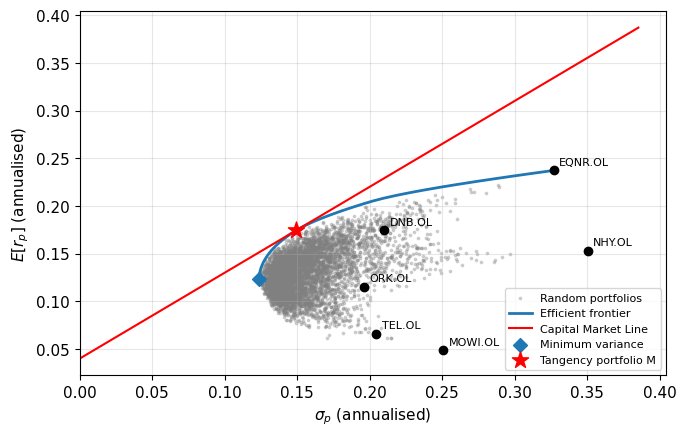

Market price of risk (slope of CML): 0.9


,Min. variance,Tangency M
EQNR.OL,0.112,0.279
DNB.OL,0.196,0.414
NHY.OL,0.051,0.020
TEL.OL,0.241,0.000
ORK.OL,0.297,0.287
MOWI.OL,0.103,0.000


In [ ]:
from scipy.optimize import minimize

pf_raw = yf.download(PF_TICKERS, period=f"{PF_YEARS}y", auto_adjust=True, progress=False)
pf_ret = pf_raw["Close"][PF_TICKERS].dropna().pct_change().dropna()
mu = pf_ret.mean().values * 252                 # annualised expected returns
cov = pf_ret.cov().values * 252                 # annualised covariance matrix
sd = np.sqrt(np.diag(cov))
n = len(PF_TICKERS)

port_sd = lambda w: np.sqrt(w @ cov @ w)
long_only = [(0, 1)] * n
budget = {"type": "eq", "fun": lambda w: w.sum() - 1}
w0 = np.ones(n) / n

# Minimum-variance and tangency portfolios (no short sales)
w_mv = minimize(port_sd, w0, bounds=long_only, constraints=[budget]).x
w_tan = minimize(lambda w: -(w @ mu - RF) / port_sd(w), w0, bounds=long_only, constraints=[budget]).x

# Efficient frontier: minimum risk for each target return above the min-variance portfolio
targets = np.linspace(w_mv @ mu, mu.max(), 40)
front = [port_sd(minimize(port_sd, w0, bounds=long_only,
                          constraints=[budget, {"type": "eq", "fun": lambda w, t=t: w @ mu - t}]).x)
         for t in targets]

# Random portfolios
W = np.random.default_rng(0).dirichlet(np.ones(n), N_RANDOM)
rand_mu, rand_sd = W @ mu, np.sqrt(np.einsum("ij,jk,ik->i", W, cov, W))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(rand_sd, rand_mu, s=3, alpha=0.3, color="grey", label="Random portfolios")
ax.plot(front, targets, color="tab:blue", lw=2, label="Efficient frontier")
ax.scatter(sd, mu, color="black", zorder=3)
for t, x, y in zip(PF_TICKERS, sd, mu):
    ax.annotate(t, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
s_m, m_m = port_sd(w_tan), w_tan @ mu
xs = np.linspace(0, max(sd.max(), s_m) * 1.1, 50)
ax.plot(xs, RF + (m_m - RF) / s_m * xs, color="red", lw=1.5, label="Capital Market Line")
ax.scatter([port_sd(w_mv)], [w_mv @ mu], color="tab:blue", marker="D", s=50, zorder=4, label="Minimum variance")
ax.scatter([s_m], [m_m], color="red", marker="*", s=150, zorder=4, label="Tangency portfolio M")
ax.set_xlabel(r"$\sigma_p$ (annualised)"); ax.set_ylabel(r"$E[r_p]$ (annualised)")
ax.set_xlim(left=0); ax.legend(fontsize=8, loc="lower right")
save(fig, "frontier")

print("Market price of risk (slope of CML):", round((m_m - RF) / s_m, 3))
pd.DataFrame({"Min. variance": w_mv, "Tangency M": w_tan}, index=PF_TICKERS).round(3)

## 6. Diversification: risk against number of stocks (block 2)

Draw random equally weighted portfolios of 1, 2, 3 ... stocks and plot their average volatility. The curve flattens at the level of market (systematic) risk: the part that cannot be diversified away.

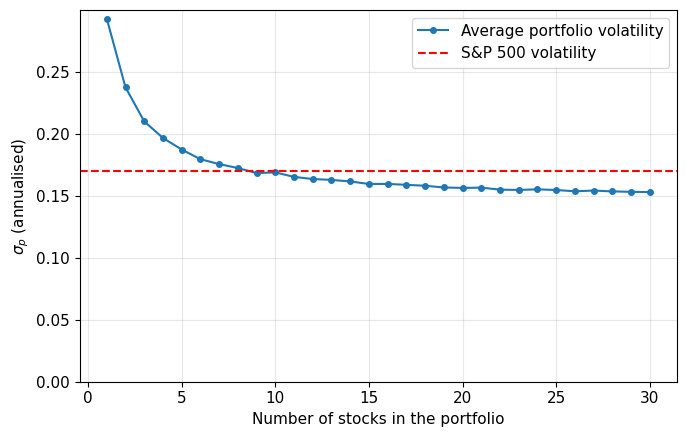

1 stock: 29.3%   30 stocks: 15.3%   S&P 500: 17.0%


In [ ]:
DIV_TICKERS = ["AAPL", "MSFT", "AMZN", "GOOGL", "META", "NVDA", "JPM", "JNJ", "PG", "KO",
               "PEP", "WMT", "XOM", "CVX", "UNH", "HD", "MRK", "PFE", "CSCO", "INTC",
               "ORCL", "IBM", "MCD", "NKE", "DIS", "BA", "CAT", "GS", "V", "MA"]
DIV_YEARS, DRAWS = 5, 300

dv_raw = yf.download(DIV_TICKERS + ["^GSPC"], period=f"{DIV_YEARS}y", auto_adjust=True, progress=False)
dv_ret = dv_raw["Close"].dropna().pct_change().dropna()
stocks = dv_ret[DIV_TICKERS]
rng = np.random.default_rng(1)
Ns = range(1, len(DIV_TICKERS) + 1)
avg_sd = [np.mean([stocks[rng.choice(DIV_TICKERS, N, replace=False)].mean(axis=1).std() * np.sqrt(252)
                   for _ in range(DRAWS)]) for N in Ns]
mkt_sd = dv_ret["^GSPC"].std() * np.sqrt(252)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(list(Ns), avg_sd, "o-", color="tab:blue", ms=4, label="Average portfolio volatility")
ax.axhline(mkt_sd, color="red", ls="--", label="S&P 500 volatility")
ax.set_xlabel("Number of stocks in the portfolio"); ax.set_ylabel(r"$\sigma_p$ (annualised)")
ax.set_ylim(bottom=0); ax.legend()
save(fig, "diversification")
print(f"1 stock: {avg_sd[0]:.1%}   {len(DIV_TICKERS)} stocks: {avg_sd[-1]:.1%}   S&P 500: {mkt_sd:.1%}")

## 7. Betas: how strongly does each stock follow the market?

$\beta_i = \dfrac{\sigma_{im}}{\sigma_m^2}$, estimated from **weekly** returns over the last five years (weekly rather than daily avoids a downward bias for stocks that trade less often).
US stocks are measured against the S&P 500, Norwegian stocks against the Oslo Børs Benchmark Index (OSEBX).

In [ ]:
# --- Settings for the betas ---------------------------------------------------
BETA_YEARS = 5
BETA_GROUPS = {
    "US stocks vs S&P 500": ("^GSPC", ["NVDA", "TSLA", "AAPL", "MSFT", "JPM", "WMT", "KO", "JNJ"]),
    "Norwegian stocks vs OSEBX": ("OSEBX.OL", ["NOD.OL", "KOG.OL", "DNB.OL", "EQNR.OL",
                                              "NHY.OL", "MOWI.OL", "ORK.OL", "TEL.OL"]),
}

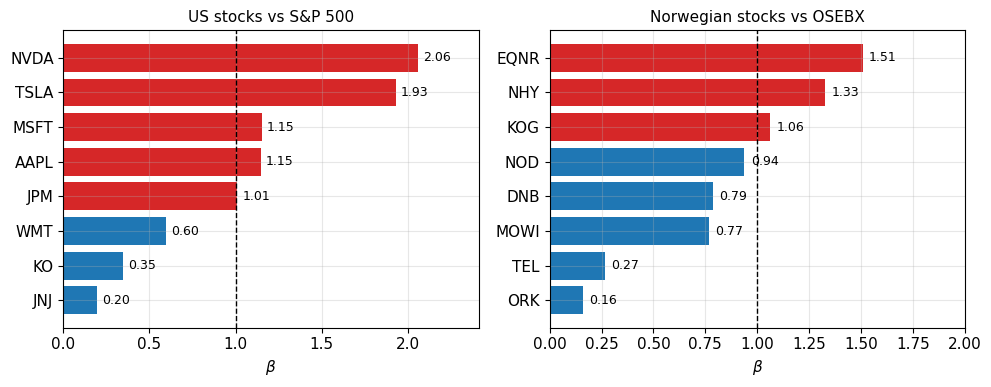

,US stocks vs S&P 500,Norwegian stocks vs OSEBX
AAPL,1.15,NaN
DNB.OL,NaN,0.79
EQNR.OL,NaN,1.51
JNJ,0.20,NaN
JPM,1.01,NaN
KO,0.35,NaN
KOG.OL,NaN,1.06
MOWI.OL,NaN,0.77
MSFT,1.15,NaN
NHY.OL,NaN,1.33


In [ ]:
def estimate_betas(market, stocks, years):
    raw = yf.download([market] + stocks, period=f"{years}y", auto_adjust=True, progress=False)
    weekly = raw["Close"].resample("W-FRI").last()
    r = weekly.pct_change().dropna(how="all")
    out = {}
    for s in stocks:
        pair = r[[s, market]].dropna()
        if len(pair) > 50:
            out[s] = pair[s].cov(pair[market]) / pair[market].var()
    return pd.Series(out).sort_values()

betas = {}
for name, (market, stocks) in BETA_GROUPS.items():
    try:
        betas[name] = estimate_betas(market, stocks, BETA_YEARS)
    except Exception as e:
        print(f"Skipped '{name}': {e}")

fig, axes = plt.subplots(1, len(betas), figsize=(10, 4), squeeze=False)
for ax, (name, b) in zip(axes[0], betas.items()):
    labels = [t.replace(".OL", "") for t in b.index]
    ax.barh(labels, b.values, color=["tab:red" if v > 1 else "tab:blue" for v in b.values])
    ax.axvline(1, color="black", ls="--", lw=1)
    for y, v in enumerate(b.values):
        ax.text(v + 0.03, y, f"{v:.2f}", va="center", fontsize=9)
    ax.set_title(name, fontsize=11); ax.set_xlabel(r"$\beta$")
    ax.set_xlim(0, max(2.0, b.max() + 0.35))
save(fig, "betas")
pd.DataFrame(betas).round(2)

## 8. Download everything for Overleaf

In [ ]:
# --- 4. Caption data for LaTeX + download --------------------------------------
with open(f"{OUT}/marketdata_info.tex", "w") as f:
    f.write("% Written by the Colab notebook - do not edit by hand\n")
    f.write(f"\\renewcommand{{\\mdStart}}{{{info['start']}}}\n")
    f.write(f"\\renewcommand{{\\mdRetStart}}{{{info['retstart']}}}\n")
    f.write(f"\\renewcommand{{\\mdEnd}}{{{info['end']}}}\n")
    f.write(f"\\renewcommand{{\\mdNprice}}{{{info['nprice']}}}\n")
    f.write(f"\\renewcommand{{\\mdNret}}{{{info['nret']}}}\n")
print(open(f"{OUT}/marketdata_info.tex").read())

shutil.make_archive("chapter3_figures", "zip", OUT)
try:
    from google.colab import files
    files.download("chapter3_figures.zip")
except ImportError:
    print("Not in Colab - files are in", os.path.abspath(OUT))

% Written by the Colab notebook - do not edit by hand
\renewcommand{\mdStart}{10 October 2025}
\renewcommand{\mdRetStart}{13 October 2025}
\renewcommand{\mdEnd}{9 October 2026}
\renewcommand{\mdNprice}{251}
\renewcommand{\mdNret}{250}



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>